# Practical 3 – 5 Qubit Quantum Fourier Transform

**Problem Statement:** Implementing a 5 qubit Quantum Fourier Transform.

**Objective:**
1. Understand the Quantum Fourier Transform
2. Create a 5 qubit Quantum Fourier Transform

**Outcome:** Displays the circuit for a 5 qubit Quantum Fourier Transform.

**Theory:** The QFT is the quantum version of the discrete Fourier transform. For n qubits (N = 2ⁿ):

$$QFT|x\rangle = \frac{1}{\sqrt{N}}\sum_{k=0}^{N-1} e^{2\pi i\,xk/N}|k\rangle$$

It changes a number from the *computational basis* to the *Fourier basis*, where the number is stored as rotation
angles (phases) of the qubits. It is built from **Hadamard** gates, **controlled phase rotations** CP(π/2ᵏ) and a final
set of **SWAP** gates, and is a key part of Shor's algorithm and Quantum Phase Estimation.

**Algorithm (for each qubit j from the most significant down):**
1. Apply H to qubit j
2. For every lower qubit k apply a controlled phase CP(π / 2^(j−k)) controlled by k on target j
3. Finally swap qubits to reverse their order

In [1]:
# Run this cell first in Google Colab (installs Qiskit + simulator)
%pip install -q qiskit qiskit-aer matplotlib pylatexenc

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.3 -> 26.3
[notice] To update, run: C:\Users\jadha\AppData\Local\Temp\claude\efb368ed25e968d0\a89940ab-0696-4fca-91e1-025ecd80d2c1\scratchpad\qenv\Scripts\python.exe -m pip install --upgrade pip


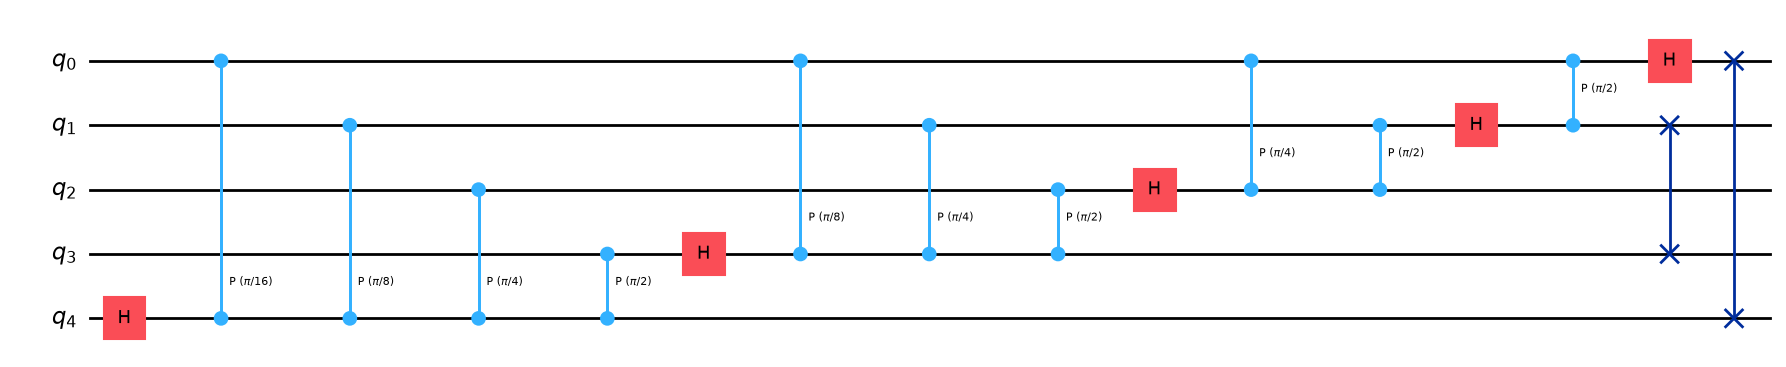

In [2]:
import numpy as np
from qiskit import QuantumCircuit, transpile
from qiskit.quantum_info import Statevector, Operator
from qiskit.visualization import plot_bloch_multivector, plot_histogram
from qiskit_aer import AerSimulator

def qft_rotations(circuit, n):
    """Recursively apply H and controlled-phase rotations to the first n qubits."""
    if n == 0:
        return circuit
    n -= 1
    circuit.h(n)
    for qubit in range(n):
        circuit.cp(np.pi / 2 ** (n - qubit), qubit, n)
    qft_rotations(circuit, n)

def swap_registers(circuit, n):
    for qubit in range(n // 2):
        circuit.swap(qubit, n - qubit - 1)
    return circuit

def qft(n):
    circuit = QuantumCircuit(n, name="QFT")
    qft_rotations(circuit, n)
    swap_registers(circuit, n)
    return circuit

N = 5
qft5 = qft(N)
qft5.draw('mpl', fold=-1)

### Verify our circuit against the mathematical QFT matrix

In [3]:
dim = 2 ** N
omega = np.exp(2j * np.pi / dim)
qft_matrix = np.array([[omega ** (x * k) for x in range(dim)] for k in range(dim)]) / np.sqrt(dim)

print("Our 5 qubit QFT circuit == QFT matrix :", Operator(qft5).equiv(Operator(qft_matrix)))

Our 5 qubit QFT circuit == QFT matrix : True


### Example – encode the number 5 in the Fourier basis
Prepare |00101⟩ = |5⟩, apply the QFT and look at the Bloch spheres: every qubit is now in an equal superposition
with a different phase (rotation) that encodes the number 5.

Input binary: 00101


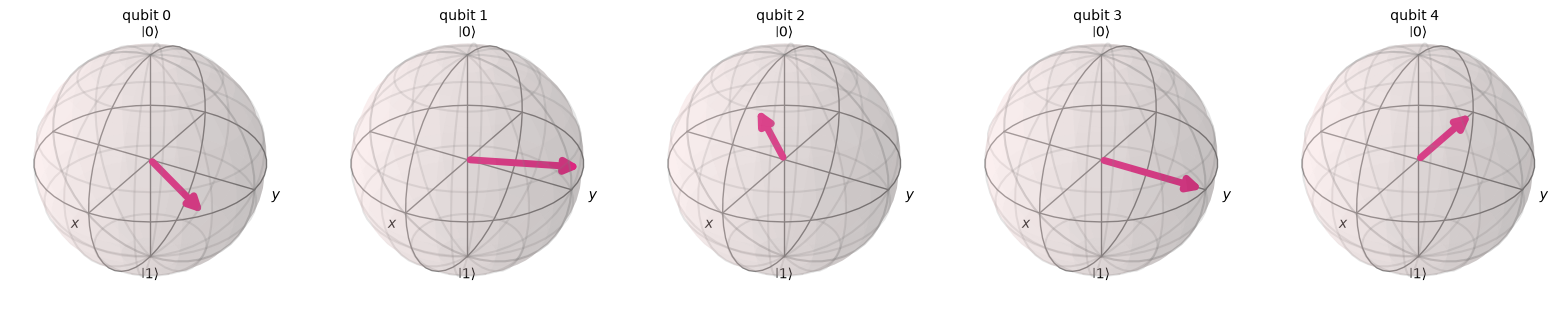

In [4]:
number = 5
qc = QuantumCircuit(N)
for i, bit in enumerate(reversed(format(number, f'0{N}b'))):
    if bit == '1':
        qc.x(i)
qc.barrier()
qc.append(qft5.to_gate(), range(N))
print("Input binary:", format(number, f'0{N}b'))
plot_bloch_multivector(Statevector(qc))

### Inverse QFT gets the number back

Measured: {'00101': 1024} -> {5: 1024}


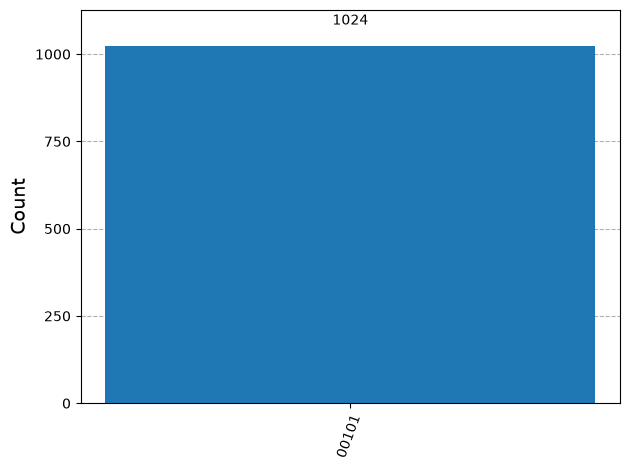

In [5]:
qc_full = qc.copy()
qc_full.append(qft5.inverse().to_gate(label="QFT†"), range(N))
qc_full.measure_all()

sim = AerSimulator()
counts = sim.run(transpile(qc_full, sim), shots=1024).result().get_counts()
print("Measured:", counts, "->", {int(k, 2): v for k, v in counts.items()})
plot_histogram(counts)

**Conclusion:** We built a 5 qubit QFT from Hadamard, controlled-phase and SWAP gates, displayed the circuit, verified
that it equals the mathematical QFT matrix, and showed that QFT followed by inverse QFT returns the original number (5).